# Module 07, Part 2: From an autoencoder to a variational autoencoder

This notebook is the runnable companion to Part 2 of the Module 07 learning content.
It checks, with code:

1. Why an ordinary autoencoder cannot be used to generate new images.
2. The two terms of the variational autoencoder's objective, and that the closed-form KL divergence is correct.
3. That the evidence lower bound (ELBO) really is a lower bound, and that the gap is exactly the KL divergence from the true posterior,
   on a model small enough to compute everything exactly.
4. That the reparameterization trick gives an unbiased gradient with low variance, and that without it the encoder gets no gradient from the
   reconstruction term.

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
class AE(nn.Module):
    """Encoder, bottleneck of size d_latent, decoder. With linear=True there are no hidden layers or activations."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, linear=False):
        super().__init__()
        if linear:
            self.enc = nn.Linear(d_in, d_latent)
            self.dec = nn.Linear(d_latent, d_in)
        else:
            self.enc = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_latent))
            self.dec = nn.Sequential(nn.Linear(d_latent, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        return self.decode(self.encode(x))


def train_ae(model, X, epochs=300, lr=2e-3, batch_size=64, noise=0.0, seed=0):
    """Train with mean squared error. noise > 0 corrupts the input but still rebuilds the clean image (a denoising autoencoder).
    Returns the mean loss of each epoch."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for _ in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        total = 0.0
        for i in range(0, len(X), batch_size):
            xb = X[perm[i:i + batch_size]]
            xin = xb + noise * torch.randn(xb.shape, generator=g) if noise > 0 else xb
            loss = ((model(xin) - xb) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        hist.append(total / len(X))
    return hist


@torch.no_grad()
def reconstruction_mse(model, X):
    return ((model(X) - X) ** 2).mean().item()


def pca_mse(X_train, X_eval, k):
    """Mean squared error of rebuilding X_eval from the top k principal components of X_train."""
    X_train = X_train.numpy().astype(np.float64)
    X_eval = X_eval.numpy().astype(np.float64)
    mu = X_train.mean(0)
    _, _, Vt = np.linalg.svd(X_train - mu, full_matrices=False)
    P = Vt[:k]
    rec = (X_eval - mu) @ P.T @ P + mu
    return float(((rec - X_eval) ** 2).mean())

In [4]:
class VAE(nn.Module):
    """Gaussian encoder q(z|x), Bernoulli-on-intensity decoder p(x|z). With n_classes > 0 both networks also see a one-hot label."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, n_classes=0):
        super().__init__()
        self.d_latent, self.n_classes = d_latent, n_classes
        self.enc = nn.Sequential(nn.Linear(d_in + n_classes, d_hidden), nn.ReLU())
        self.mu = nn.Linear(d_hidden, d_latent)
        self.logvar = nn.Linear(d_hidden, d_latent)
        self.dec = nn.Sequential(nn.Linear(d_latent + n_classes, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x, c=None):
        h = self.enc(x if c is None else torch.cat([x, c], 1))
        return self.mu(h), self.logvar(h)

    def decode(self, z, c=None):
        """Returns logits; apply a sigmoid to get pixel intensities."""
        return self.dec(z if c is None else torch.cat([z, c], 1))

    @staticmethod
    def reparameterize(mu, logvar, generator=None):
        eps = torch.randn(mu.shape, generator=generator)
        return mu + torch.exp(0.5 * logvar) * eps

    def forward(self, x, c=None):
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, c), mu, logvar


def kl_to_standard_normal(mu, logvar):
    """KL( N(mu, sigma^2) || N(0, 1) ) summed over latent dimensions, one value per example."""
    return 0.5 * (mu ** 2 + torch.exp(logvar) - 1.0 - logvar).sum(1)


def reconstruction_nll(logits, x):
    """Bernoulli negative log-likelihood of the pixel intensities, summed over pixels, one value per example."""
    return F.binary_cross_entropy_with_logits(logits, x, reduction="none").sum(1)


def elbo_terms(model, x, c=None):
    """One-sample estimate of the two terms of the negative ELBO, each averaged over the batch."""
    logits, mu, logvar = model(x, c)
    return reconstruction_nll(logits, x).mean(), kl_to_standard_normal(mu, logvar).mean()


def train_vae(model, X, y_onehot=None, epochs=200, lr=2e-3, batch_size=64, beta=1.0, anneal_epochs=0, seed=0):
    """Minimize recon + beta * KL. With anneal_epochs > 0, beta rises linearly from 0 to its final value over that many epochs.
    Returns a list of (reconstruction, KL) epoch averages."""
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        b = beta * min(1.0, ep / anneal_epochs) if anneal_epochs > 0 else beta
        perm = torch.randperm(len(X), generator=g)
        sr = sk = 0.0
        for i in range(0, len(X), batch_size):
            idx = perm[i:i + batch_size]
            xb = X[idx]
            cb = y_onehot[idx] if y_onehot is not None else None
            rec, kl = elbo_terms(model, xb, cb)
            loss = rec + b * kl
            opt.zero_grad()
            loss.backward()
            opt.step()
            sr += rec.item() * len(xb)
            sk += kl.item() * len(xb)
        hist.append((sr / len(X), sk / len(X)))
    return hist


@torch.no_grad()
def evaluate_terms(model, X, c=None, repeats=10, seed=0):
    """Average (reconstruction, KL) over the set, using several draws of z per example."""
    torch.manual_seed(seed)
    r = k = 0.0
    for _ in range(repeats):
        rec, kl = elbo_terms(model, X, c)
        r += rec.item() / repeats
        k += kl.item() / repeats
    return r, k


@torch.no_grad()
def iwae_bound(model, x, K=1, seed=0):
    """Importance-weighted estimate of log p(x) per example, using q(z|x) as the proposal and K samples.
    K = 1 is the ELBO. As K grows the bound tightens toward log p(x)."""
    torch.manual_seed(seed)
    mu, logvar = model.encode(x)
    std = torch.exp(0.5 * logvar)
    logw = []
    for _ in range(K):
        z = mu + std * torch.randn_like(std)
        logits = model.decode(z)
        log_px_z = -reconstruction_nll(logits, x)
        log_pz = -0.5 * (z ** 2 + math.log(2 * math.pi)).sum(1)
        log_qz = -0.5 * (((z - mu) / std) ** 2 + math.log(2 * math.pi) + logvar).sum(1)
        logw.append(log_px_z + log_pz - log_qz)
    logw = torch.stack(logw, 0)
    return torch.logsumexp(logw, 0) - math.log(K)


@torch.no_grad()
def active_units(model, X, threshold=0.01):
    """Number of latent dimensions whose posterior mean varies across the data by more than the threshold (variance)."""
    mu, _ = model.encode(X)
    return int((mu.var(0) > threshold).sum().item())

In [5]:
Xtr, ytr, Xte, yte = load_data()
def show(imgs, ncols=10, title=None, size=1.0):
    n = len(imgs); nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, im in zip(np.ravel(axes), imgs):
        ax.imshow(np.asarray(im).reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    if title: fig.suptitle(title, y=1.0)
    plt.show()

## 1. Why an autoencoder is not a generator

To generate an image, you would pick a code and decode it. But which codes are valid? For an ordinary autoencoder nothing says.
The encoder is free to place the training codes anywhere, at any scale. We train an autoencoder and a variational autoencoder with
the same sizes (an 8-dimensional code) and compare what the codes look like, and what happens when we decode points drawn from a
standard normal distribution, the simplest choice of prior.

In [6]:
torch.manual_seed(0)
ae = AE(d_latent=8); train_ae(ae, Xtr, epochs=300)
vae = VAE(d_latent=8); train_vae(vae, Xtr, epochs=200, beta=1.0)
with torch.no_grad():
    z_ae = ae.encode(Xtr)
    z_vae = vae.encode(Xtr)[0]
print("per-dimension mean of the training codes")
print("  autoencoder :", np.round(z_ae.mean(0).numpy(), 2))
print("  VAE         :", np.round(z_vae.mean(0).numpy(), 2))
print("per-dimension standard deviation of the training codes")
print("  autoencoder :", np.round(z_ae.std(0).numpy(), 2))
print("  VAE         :", np.round(z_vae.std(0).numpy(), 2))

per-dimension mean of the training codes
  autoencoder : [ 0.57  0.07  0.47 -0.74  0.16 -0.02  0.41 -0.35]
  VAE         : [-0.06  0.   -0.03 -0.   -0.03 -0.    0.    0.06]
per-dimension standard deviation of the training codes
  autoencoder : [0.7  0.83 0.57 0.63 0.67 0.76 0.53 0.67]
  VAE         : [0.8  0.57 0.95 0.02 0.93 0.02 0.02 0.89]


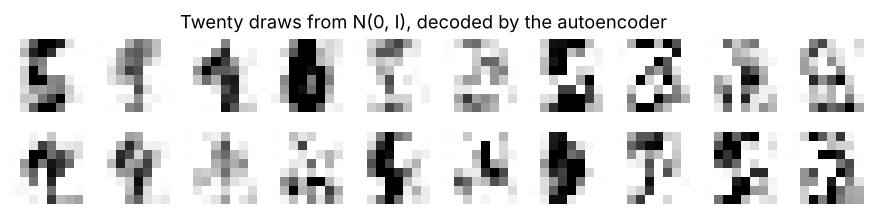

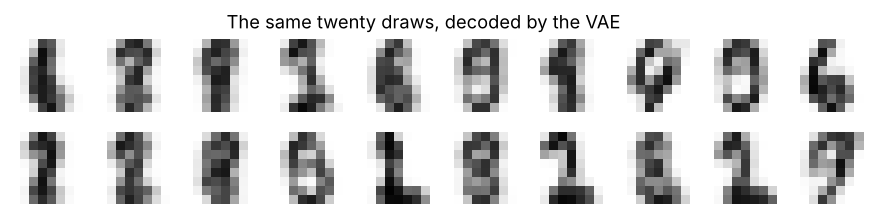

In [7]:
g = torch.Generator().manual_seed(3)
z = torch.randn(20, 8, generator=g)
with torch.no_grad():
    from_ae = ae.decode(z).clamp(0, 1)
    from_vae = torch.sigmoid(vae.decode(z))
show(from_ae, title="Twenty draws from N(0, I), decoded by the autoencoder")
show(from_vae, title="The same twenty draws, decoded by the VAE")

The autoencoder's codes are not centred on zero and are not on a unit scale, so a draw from the standard normal lands in
places the decoder was never trained on. The VAE was trained so that its codes match that distribution, so the same draws land
where the decoder has learned to produce digits. Part 5 puts a number on the difference. The rest of this notebook explains
what the VAE changes.

## 2. The objective, and the closed-form KL

A VAE assumes each image $x$ is generated by drawing a code $z \sim \mathcal{N}(0, I)$ and then drawing $x$ from a decoder
$p(x|z)$. The encoder $q(z|x) = \mathcal{N}(\mu(x), \text{diag}(\sigma^2(x)))$ is a learned approximation to the posterior over codes. Training
minimizes the negative ELBO:

$$-\text{ELBO}(x) = \underbrace{-\mathbb{E}_{q(z|x)}[\log p(x|z)]}_{\text{reconstruction}} + \underbrace{\text{KL}\big(q(z|x)\,\|\,p(z)\big)}_{\text{regularizer}}$$

For a Gaussian $q$ and a standard normal prior the KL has a closed form, $\tfrac12 \sum_j (\mu_j^2 + \sigma_j^2 - 1 - \log \sigma_j^2)$.
The check below compares that formula with a Monte Carlo estimate of $\mathbb{E}_q[\log q(z) - \log p(z)]$ for a handful of random $(\mu, \log\sigma^2)$.

In [8]:
torch.manual_seed(0)
def log_normal(z, mu, logvar):
    return -0.5 * (math.log(2 * math.pi) + logvar + (z - mu) ** 2 / torch.exp(logvar)).sum(-1)

print("closed form    Monte Carlo (200,000 draws)")
for _ in range(5):
    mu = torch.randn(1, 4); logvar = torch.randn(1, 4) * 0.5
    exact = kl_to_standard_normal(mu, logvar).item()
    z = mu + torch.exp(0.5 * logvar) * torch.randn(200_000, 4)
    mc = (log_normal(z, mu, logvar) - log_normal(z, torch.zeros(1, 4), torch.zeros(1, 4))).mean().item()
    print(f"{exact:11.4f}    {mc:11.4f}")
    assert abs(exact - mc) < 0.02

closed form    Monte Carlo (200,000 draws)
     3.9871         3.9907


     3.0649         3.0670
     3.1224         3.1261


     3.6344         3.6154
     1.6856         1.6852


## 3. The ELBO is a lower bound, and the gap is a KL divergence

The identity behind the ELBO is

$$\log p(x) = \text{ELBO}(x) + \text{KL}\big(q(z|x)\,\|\,p(z|x)\big).$$

Because the KL divergence is never negative, the ELBO can never exceed $\log p(x)$, and it is exact only when $q$ equals the true
posterior. For a neural-network decoder the true posterior is out of reach, so we cannot check this on a VAE. We can check it on a model
where everything is computable: $z \sim \mathcal{N}(0, 1)$ in one dimension and $x = w z + \epsilon$ in two dimensions with
$\epsilon \sim \mathcal{N}(0, s^2 I)$. Then $\log p(x)$ and the true posterior are exact.

In [9]:
torch.manual_seed(1)
w = torch.tensor([1.5, -0.8]); s2 = 0.25
x = torch.tensor([1.2, -0.9])

# exact marginal: x ~ N(0, w w^T + s2 I)
cov = torch.outer(w, w) + s2 * torch.eye(2)
dist = torch.distributions.MultivariateNormal(torch.zeros(2), cov)
log_px = dist.log_prob(x).item()

# exact posterior over z: Gaussian with mean m and variance v
denom = (w @ w) + s2
m_true, v_true = (w @ x) / denom, s2 / denom

def elbo(m_q, v_q, n=400_000):
    z = m_q + math.sqrt(v_q) * torch.randn(n)
    log_lik = torch.distributions.MultivariateNormal(z[:, None] * w[None], s2 * torch.eye(2)).log_prob(x)
    log_prior = torch.distributions.Normal(0.0, 1.0).log_prob(z)
    log_q = torch.distributions.Normal(m_q, math.sqrt(v_q)).log_prob(z)
    return (log_lik + log_prior - log_q).mean().item()

def kl_gauss(m1, v1, m2, v2):      # KL( N(m1, v1) || N(m2, v2) ) in one dimension
    return 0.5 * (math.log(v2 / v1) + (v1 + (m1 - m2) ** 2) / v2 - 1)

print(f"exact log p(x)                      : {log_px:.4f}")
for name, (mq, vq) in {"q = true posterior": (m_true.item(), v_true.item()),
                       "q shifted by 0.5": (m_true.item() + 0.5, v_true.item()),
                       "q twice too wide": (m_true.item(), 2 * v_true.item())}.items():
    e = elbo(mq, vq)
    gap = kl_gauss(mq, vq, m_true.item(), v_true.item())
    print(f"{name:20s} ELBO = {e:8.4f}   log p(x) - ELBO = {log_px - e:7.4f}   KL to true posterior = {gap:7.4f}")

exact log p(x)                      : -2.1720
q = true posterior   ELBO =  -2.1720   log p(x) - ELBO =  0.0000   KL to true posterior =  0.0000


q shifted by 0.5     ELBO =  -3.7373   log p(x) - ELBO =  1.5653   KL to true posterior =  1.5700


q twice too wide     ELBO =  -2.3236   log p(x) - ELBO =  0.1516   KL to true posterior =  0.1534


With the true posterior, the ELBO equals $\log p(x)$ and the gap is zero. With a worse $q$, the ELBO is lower by exactly the KL divergence
to the true posterior (the last two columns agree up to Monte Carlo error). That is why training a VAE does two jobs at once: it
improves the decoder, and it pulls the encoder towards the true posterior.

## 4. The reparameterization trick

The reconstruction term is an expectation over $z \sim q$, and $q$ depends on the encoder's parameters. To train the encoder by gradient
descent we need the gradient of that expectation. Writing $z = \mu + \sigma\epsilon$ with $\epsilon \sim \mathcal{N}(0, 1)$ moves the randomness
into $\epsilon$ and lets the gradient flow through $\mu$ and $\sigma$.

First a case where the answer is known: $f(z) = (z - 3)^2$ with $z \sim \mathcal{N}(\mu, 1)$. Then $\mathbb{E}[f] = (\mu - 3)^2 + 1$ and its derivative with
respect to $\mu$ is $2(\mu - 3)$. We estimate it two ways, with the reparameterization trick and with the score-function (REINFORCE) estimator that works
for any distribution, and look at the mean and the variance across single-sample estimates.

In [10]:
torch.manual_seed(0)
mu0, n = 0.0, 100_000
eps = torch.randn(n)
z = mu0 + eps
reparam = 2 * (z - 3)                        # d/dmu of (mu + eps - 3)^2
score = (z - 3) ** 2 * (z - mu0)             # f(z) * d/dmu log N(z; mu, 1)
print(f"true derivative                 : {2 * (mu0 - 3):.3f}")
print(f"reparameterization estimate     : mean {reparam.mean():.3f}, variance of one sample {reparam.var():.2f}")
print(f"score-function estimate         : mean {score.mean():.3f}, variance of one sample {score.var():.2f}")
print(f"ratio of variances              : {(score.var() / reparam.var()).item():.1f}")

true derivative                 : -6.000
reparameterization estimate     : mean -6.005, variance of one sample 4.01
score-function estimate         : mean -6.048, variance of one sample 224.98
ratio of variances              : 56.1


Both estimators are unbiased: their means agree with the true derivative. The variance differs. Gradient descent can tolerate noise,
but a larger variance means slower and less stable training, and the reparameterization estimator is much quieter.

Now the real model. We take one batch and compute the gradient reaching the encoder's weights in three cases: the standard VAE, a version
that samples $z$ without the trick (so the sample is a constant as far as autograd is concerned), and the same version looked at
only through the reconstruction term.

In [11]:
torch.manual_seed(0)
x = Xtr[:128]

def encoder_grad_norm(use_trick, include_kl):
    m = VAE(d_latent=8)
    mu, logvar = m.encode(x)
    eps = torch.randn_like(mu)
    z = mu + torch.exp(0.5 * logvar) * eps
    if not use_trick:
        z = z.detach()                        # a sampled number, cut off from the encoder
    loss = reconstruction_nll(m.decode(z), x).mean()
    if include_kl:
        loss = loss + kl_to_standard_normal(mu, logvar).mean()
    m.zero_grad()
    loss.backward()
    g = m.mu.weight.grad
    return 0.0 if g is None else g.norm().item()

print("gradient norm reaching the encoder (mean head)")
print(f"  reparameterized, reconstruction term only : {encoder_grad_norm(True, False):.4f}")
print(f"  sample cut off, reconstruction term only  : {encoder_grad_norm(False, False):.4f}")
print(f"  sample cut off, with the KL term          : {encoder_grad_norm(False, True):.4f}")

gradient norm reaching the encoder (mean head)
  reparameterized, reconstruction term only : 0.8336
  sample cut off, reconstruction term only  : 0.0000
  sample cut off, with the KL term          : 0.3919


With the trick, the reconstruction error tells the encoder how to move the code. Without it the reconstruction term sends the encoder nothing, and
the only thing left to learn from is the KL term, which would pull every code towards the prior and make the encoder useless for reconstruction.

## What to take away

- An ordinary autoencoder places its codes wherever it likes, so decoding a draw from a simple prior produces poor images. The VAE trains the codes
  to match a prior you can sample from.
- The objective has two terms: how well the decoder rebuilds the image, and how far the encoder's distribution is from the prior.
- The ELBO is a lower bound on $\log p(x)$, and the gap is exactly the KL divergence between the encoder's distribution and the true posterior.
- The reparameterization trick makes the reconstruction term trainable for the encoder, with far lower variance than the general-purpose estimator.